In [12]:
import numpy as np
from pathlib import Path
from helpers import load_csv_data

# Find the data folder relative to this script
data_dir=Path("data")

# Load the datasets
x_train, x_test, y_train, train_ids, test_ids = load_csv_data(data_dir)

In [56]:
import os
# some checking
print("x_train shape :", x_train.shape)
print("y_train shape :", y_train.shape)
x_col=np.genfromtxt( os.path.join(data_dir, "x_train.csv"),delimiter=",",dtype=str,max_rows=1)
print("col of x_train",x_col)
x_col=x_col[1:]#to match the def of x_train where we have removed the first index 



x_train shape : (328135, 321)
y_train shape : (328135,)
col of x_train ['Id' '_STATE' 'FMONTH' 'IDATE' 'IMONTH' 'IDAY' 'IYEAR' 'DISPCODE' 'SEQNO'
 '_PSU' 'CTELENUM' 'PVTRESD1' 'COLGHOUS' 'STATERES' 'CELLFON3' 'LADULT'
 'NUMADULT' 'NUMMEN' 'NUMWOMEN' 'CTELNUM1' 'CELLFON2' 'CADULT' 'PVTRESD2'
 'CCLGHOUS' 'CSTATE' 'LANDLINE' 'HHADULT' 'GENHLTH' 'PHYSHLTH' 'MENTHLTH'
 'POORHLTH' 'HLTHPLN1' 'PERSDOC2' 'MEDCOST' 'CHECKUP1' 'BPHIGH4' 'BPMEDS'
 'BLOODCHO' 'CHOLCHK' 'TOLDHI2' 'CVDSTRK3' 'ASTHMA3' 'ASTHNOW' 'CHCSCNCR'
 'CHCOCNCR' 'CHCCOPD1' 'HAVARTH3' 'ADDEPEV2' 'CHCKIDNY' 'DIABETE3'
 'DIABAGE2' 'SEX' 'MARITAL' 'EDUCA' 'RENTHOM1' 'NUMHHOL2' 'NUMPHON2'
 'CPDEMO1' 'VETERAN3' 'EMPLOY1' 'CHILDREN' 'INCOME2' 'INTERNET' 'WEIGHT2'
 'HEIGHT3' 'PREGNANT' 'QLACTLM2' 'USEEQUIP' 'BLIND' 'DECIDE' 'DIFFWALK'
 'DIFFDRES' 'DIFFALON' 'SMOKE100' 'SMOKDAY2' 'STOPSMK2' 'LASTSMK2'
 'USENOW3' 'ALCDAY5' 'AVEDRNK2' 'DRNK3GE5' 'MAXDRNKS' 'FRUITJU1' 'FRUIT1'
 'FVBEANS' 'FVGREEN' 'FVORANG' 'VEGETAB1' 'EXERANY2' 'EXRACT11'

analyse of x_train


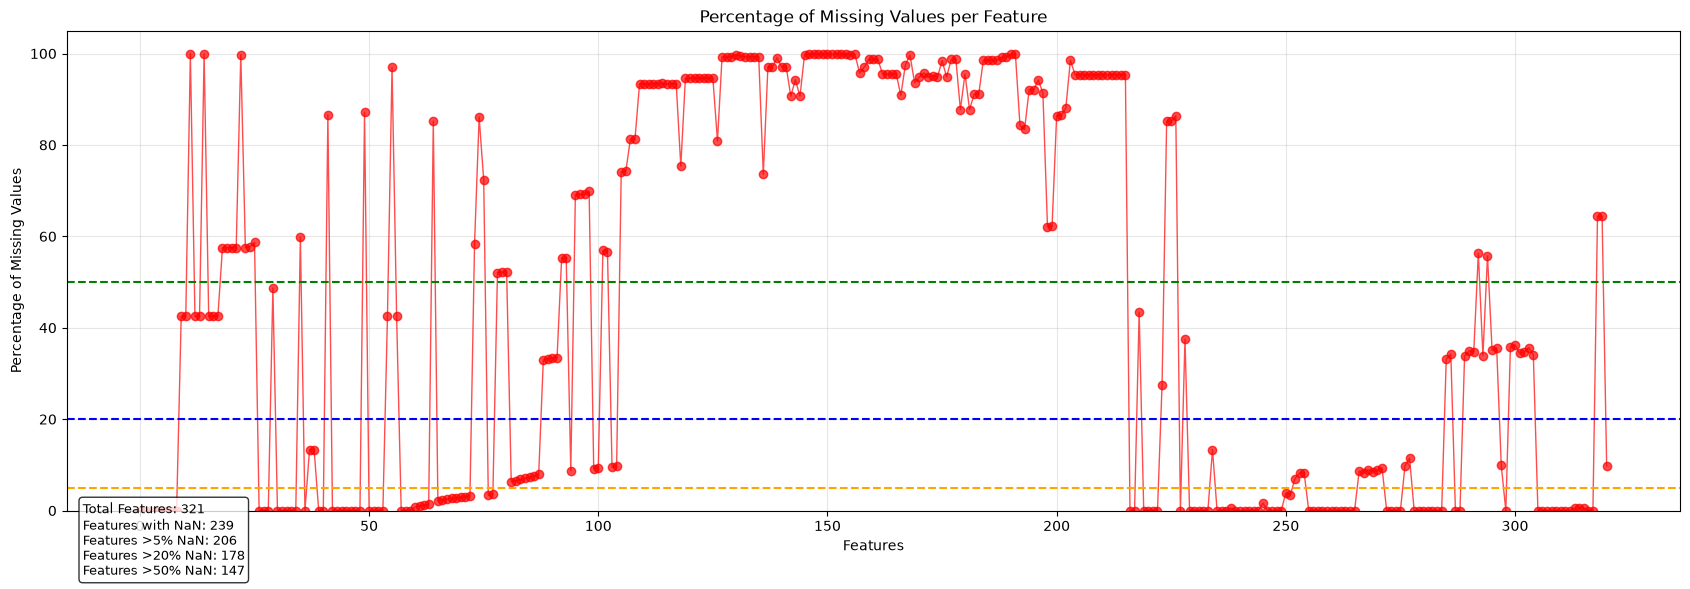

In [57]:
import matplotlib.pyplot as plt


missing_percent= np.isnan(x_train).mean(axis=0)*100
feature_idx=np.arange(len(missing_percent))

#calculate statitics
n_features=len(missing_percent)
col_with_nan=missing_percent[missing_percent>0]
col_above_5=missing_percent[missing_percent>5]
col_above_20=missing_percent[missing_percent>20]
col_above_50=missing_percent[missing_percent>50]

fig, ax = plt.subplots(figsize=(17, 6))
ax.plot(feature_idx, missing_percent, marker='o', color="red",linewidth=1,alpha=0.7)
ax.axhline(y=5, color='orange', linestyle='--', label='5% Threshold')
ax.axhline(y=20, color='blue', linestyle='--', label='20% Threshold')
ax.axhline(y=50, color='green', linestyle='--', label='50% Threshold')

plt.xlabel("Features")
plt.ylabel("Percentage of Missing Values")
plt.title("Percentage of Missing Values per Feature")
ax.set_ylim(0, 105)
ax.grid(alpha=0.3)
stats_text = f"Total Features: {n_features}\nFeatures with NaN: {len(col_with_nan)}\nFeatures >5% NaN: {len(col_above_5)}\nFeatures >20% NaN: {len(col_above_20)}\nFeatures >50% NaN: {len(col_above_50)}"
ax.text(0.01, 0.02, stats_text, transform=ax.transAxes, fontsize=9, verticalalignment='top', bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))
plt.tight_layout()
plt.show()



In [58]:
#maybe some col that we can remove 
col_above_95=missing_percent[missing_percent>95]
print("nbr of col taht have more then 95 percent of missing data :"+str(len(col_above_95)))
idx_above_95=np.where(missing_percent>95)[0]
sorted_idx=idx_above_95[np.argsort(missing_percent[idx_above_95])[::-1]]
for i in sorted_idx:
    print(f"{x_col[i]}:{missing_percent[i]:.2f}%")


nbr of col taht have more then 95 percent of missing data :68
LADULT:99.99%
COLGHOUS:99.99%
PCDMDECN:99.95%
ASDRVIST:99.93%
ASERVIST:99.93%
ASNOSLEP:99.90%
ASINHALR:99.85%
ASTHMED3:99.85%
ASYMPTOM:99.85%
ASACTLIM:99.85%
ASRCHKUP:99.85%
ASATTACK:99.85%
STREHAB1:99.84%
PCPSADE1:99.82%
HAREHAB1:99.76%
ASTHMAGE:99.76%
VINOCRE2:99.76%
CCLGHOUS:99.76%
HPVADSHT:99.67%
VIEYEXM2:99.43%
VIMACDG2:99.28%
VIGLUMA2:99.28%
VICTRCT4:99.28%
VIINSUR2:99.28%
VIPRFVS2:99.28%
VIREDIF3:99.28%
VIDFCLT2:99.28%
PCPSARS1:99.20%
PSATIME:99.20%
CDHELP:99.06%
LENGEXAM:98.87%
RLIVPAIN:98.72%
RDUCSTRK:98.72%
RDUCHART:98.72%
PROFEXAM:98.71%
CASTHNO2:98.53%
PSATEST1:98.52%
PCPSARE1:98.52%
PCPSADI1:98.52%
PCPSAAD2:98.51%
HPLSTTST:98.42%
HPVADVC2:97.53%
CDDISCUS:97.07%
CDSOCIAL:97.07%
CDASSIST:97.06%
CDHOUSE:97.06%
ASPUNSAF:97.00%
NUMPHON2:96.99%
HOWLONG:95.79%
CVDASPRN:95.72%
ARTHEDU:95.56%
ARTHEXER:95.56%
ARTHWGT:95.56%
ARTTODAY:95.56%
LSTBLDS3:95.52%
ADANXEV:95.41%
MISTMNT:95.41%
LSATISFY:95.41%
EMTSUPRT:95.40%
ADMOV

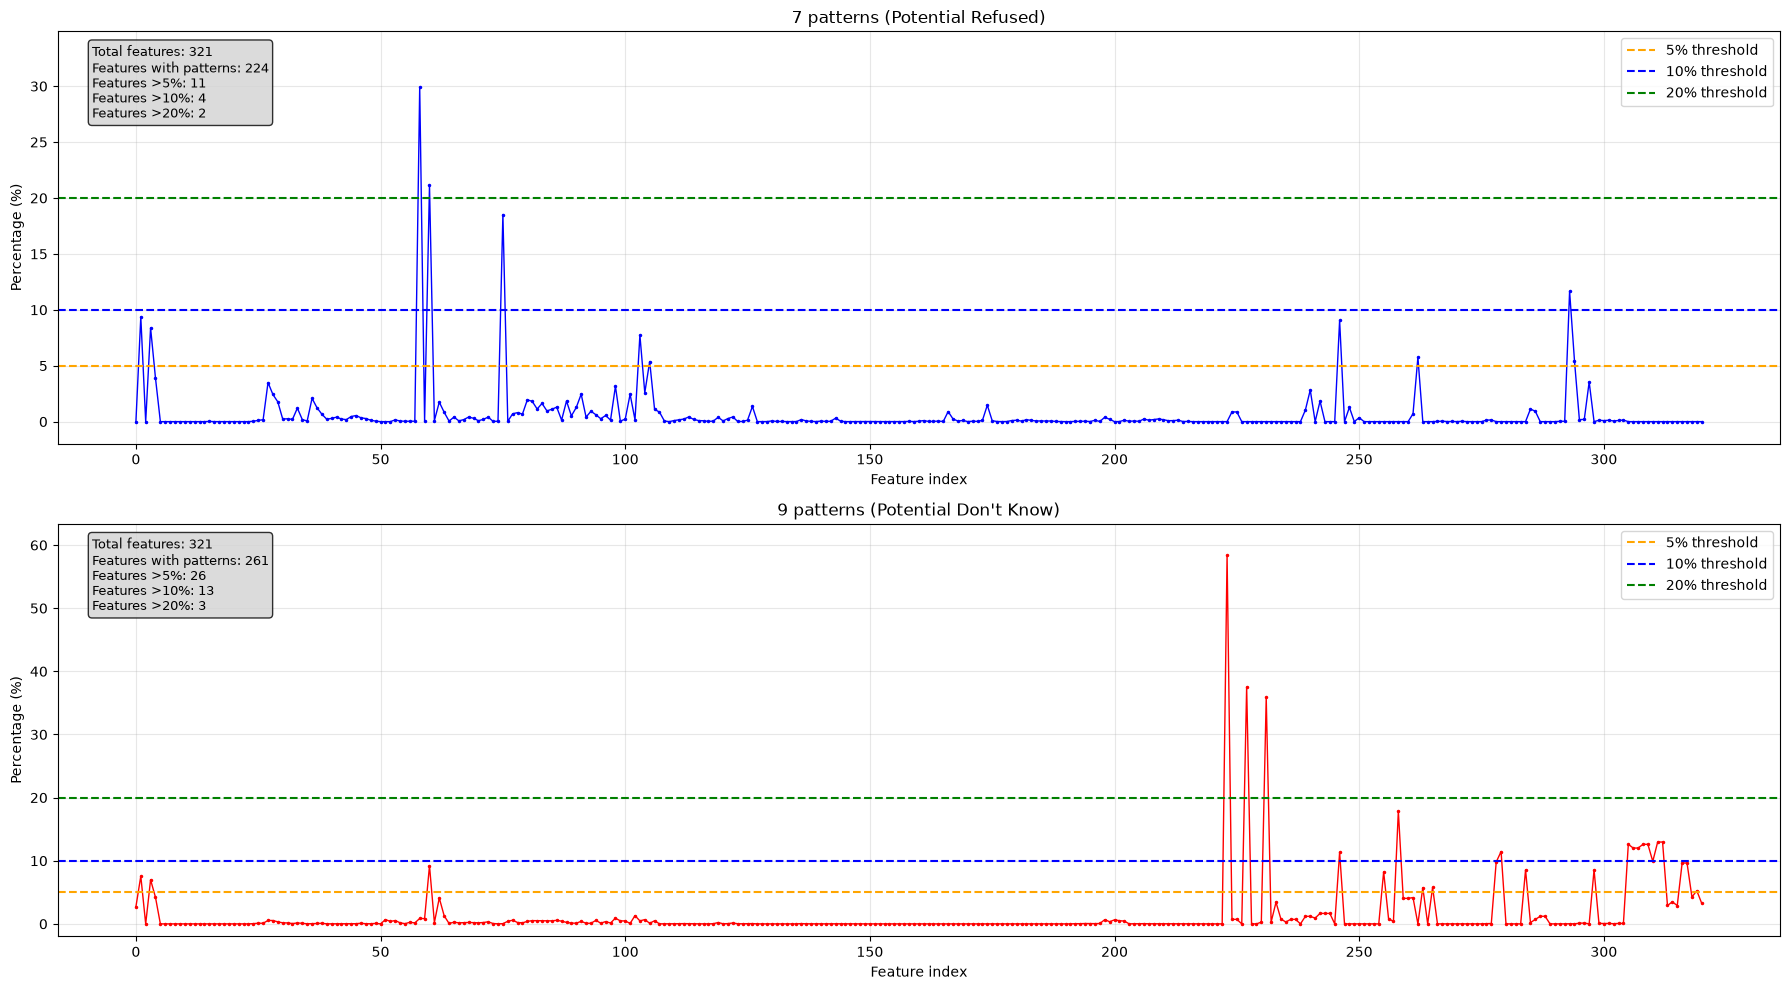

In [59]:
#now we can look at the data where we have written don't know or refused with 9 and 7 patern 

# Potential missing-value codes
refused_patterns = [7, 77, 777, 7777, 77777, 777777]
dont_know_patterns = [9, 99, 999, 9999, 99999, 999999]

# Percentage per column
refused_percent = np.zeros(x_train.shape[1])
dont_know_percent = np.zeros(x_train.shape[1])

for code in refused_patterns:
    refused_percent += np.sum(x_train == code, axis=0)

for code in dont_know_patterns:
    dont_know_percent += np.sum(x_train == code, axis=0)

refused_percent = refused_percent / x_train.shape[0] * 100
dont_know_percent = dont_know_percent / x_train.shape[0] * 100

feature_idx = np.arange(x_train.shape[1])
n_features = x_train.shape[1]

fig, axes = plt.subplots(2, 1, figsize=(18, 10))

# Plot configurations
plots = [
    (axes[0], refused_percent, "7 patterns (Potential Refused)", "blue"),
    (axes[1], dont_know_percent, "9 patterns (Potential Don't Know)", "red")
]

for ax, percentages, title, color in plots:

    # Plot percentages
    ax.plot(feature_idx, percentages, marker='o',
            markersize=1.5, linewidth=1, color=color)

    # Threshold lines
    ax.axhline(y=5, color="orange", linestyle="--", label="5% threshold")
    ax.axhline(y=10, color="blue", linestyle="--", label="10% threshold")
    ax.axhline(y=20, color="green", linestyle="--", label="20% threshold")

    # Statistics
    n_with = np.sum(percentages > 0)
    n_above_5 = np.sum(percentages > 5)
    n_above_10 = np.sum(percentages > 10)
    n_above_20 = np.sum(percentages > 20)

    stats_text = (
        f"Total features: {n_features}\n"
        f"Features with patterns: {n_with}\n"
        f"Features >5%: {n_above_5}\n"
        f"Features >10%: {n_above_10}\n"
        f"Features >20%: {n_above_20}"
    )

    # Add statistics box inside graph
    ax.text(
        0.02, 0.97, stats_text,
        transform=ax.transAxes,
        fontsize=9,
        verticalalignment="top",
        bbox=dict(boxstyle="round", facecolor="lightgray", alpha=0.8)
    )

    ax.set_xlabel("Feature index")
    ax.set_ylabel("Percentage (%)")
    ax.set_title(title)
    ax.set_ylim(-2, max(25, np.max(percentages) + 5))
    ax.grid(alpha=0.3)
    ax.legend(loc="upper right")

plt.tight_layout()
plt.show()

The pattern we have tested is not necessarly for teh unknown and refused questions, it could also be juste some sclar eg for the month. Need to come back later at this....
For now we can consider that we replace the 7 and 9 patterns with Nan, and removed the cols bigger the 95%. 
We need also to look at the type of input, if continous or categortical 

In [60]:
import numpy as np

def identify_feature_types(X, threshold=10):
    categorical = []
    continuous = []

    for i in range(X.shape[1]):

        # Select column and remove NaNs
        column = X[:, i]
        column = column[~np.isnan(column)]

        # Count unique values
        n_unique = len(np.unique(column))

        # Classify
        if n_unique <= threshold:
            categorical.append(i)#if use 10 or less value, then it is categorical
        else:
            continuous.append(i)

    return np.array(categorical, dtype=int), np.array(continuous, dtype=int)

In [61]:
categorical_idx, continuous_idx = identify_feature_types(x_train)

print("Categorical features:", len(categorical_idx))
print("Continuous features:", len(continuous_idx))

Categorical features: 219
Continuous features: 102


Begin with cleaning data 

In [66]:
classes, counts = np.unique(y_train, return_counts=True)

for c, count in zip(classes, counts):
    print(f"Class {c}: {count} observations ({count / len(y_train) * 100:.2f}%)")

rng = np.random.default_rng(42)

# split data 80% and 20%
indices = rng.permutation(len(y_train))
n_train = int(0.8 * len(y_train))
train_idx = indices[:n_train]
val_idx = indices[n_train:]
X_tr = x_train[train_idx]
X_val = x_train[val_idx]
y_tr = y_train[train_idx]
y_val = y_train[val_idx]

#find the majority class 
classes, counts = np.unique(y_tr, return_counts=True)
majority_class = classes[np.argmax(counts)]
print("Majority class:", majority_class)

#makes predictions
y_pred = np.full(len(y_val), majority_class)
accuracy = np.mean(y_pred == y_val)
print(f"Baseline accuracy: {accuracy:.2%}")#but here we always do wrong for the 1 so the baseline accuracy here si not a good crteria 

# here we see it more explicitly 
# Positive class is +1
TP = np.sum((y_val == 1) & (y_pred == 1))
FN = np.sum((y_val == 1) & (y_pred == -1))
FP = np.sum((y_val == -1) & (y_pred == 1))
TN = np.sum((y_val == -1) & (y_pred == -1))

recall = TP / (TP + FN)

print("True positives:", TP)
print("False negatives:", FN)
print("Recall:", recall)



Class -1: 299160 observations (91.17%)
Class 1: 28975 observations (8.83%)
Majority class: -1
Baseline accuracy: 91.12%
True positives: 0
False negatives: 5825
Recall: 0.0


It would be good to try to balanced the data set, using class weight, oversampling, undersampling.... 
we can do it after....

In [68]:
#but we can use a stratified training to have something a little better
#so instead of randomly splitting everyone together, we split each class separately.
#  Therefore, both subsets retain nearly the same class proportions as your original dataset
rng = np.random.default_rng(42)

train_idx = []
val_idx = []

for c in np.unique(y_train):
    idx = np.where(y_train == c)[0]
    idx = rng.permutation(idx)

    n = int(0.8 * len(idx))

    train_idx.extend(idx[:n])
    val_idx.extend(idx[n:])

train_idx = np.array(train_idx)
val_idx = np.array(val_idx)

X_tr = x_train[train_idx]
X_val = x_train[val_idx]

y_tr = y_train[train_idx]
y_val = y_train[val_idx]

for name, y in [("Train", y_tr), ("Validation", y_val)]:
    print(name)
    print("Class +1:", np.mean(y == 1) * 100, "%")
    print("Class -1:", np.mean(y == -1) * 100, "%")

Train
Class +1: 8.830207079403294 %
Class -1: 91.1697929205967 %
Validation
Class +1: 8.830207079403294 %
Class -1: 91.1697929205967 %


now we are going to handle the missing value and everything that we have anaylse before

In [77]:
X_tr_clean = X_tr.copy()
X_val_clean = X_val.copy()

patterns = [7, 77, 777, 7777, 77777, 777777,
            9, 99, 999, 9999, 99999, 999999]

X_tr_clean[np.isin(X_tr_clean, patterns)] = np.nan
X_val_clean[np.isin(X_val_clean, patterns)] = np.nan

# Percentage of missing values in each column
missing_percent = np.mean(np.isnan(X_tr_clean), axis=0) * 100 # axis 0 bc we do it by col 

# Keep columns with <= 95% missing values
keep = missing_percent <= 95

print("Original features:", X_tr_clean.shape[1])
print("Features removed:", np.sum(~keep))
print("Features kept:", np.sum(keep))

X_tr_filtered = X_tr_clean[:, keep]
X_val_filtered = X_val_clean[:, keep]
x_columns_filtered = x_col[keep]

print("Training shape:", X_tr_filtered.shape)
print("Validation shape:", X_val_filtered.shape)



Original features: 321
Features removed: 71
Features kept: 250
Training shape: (262508, 250)
Validation shape: (65627, 250)


Now we need to remplace the nan that we still have with some values using medians or modes if it is continous or categorical features. 

In [78]:
categorical_idx, continuous_idx = identify_feature_types(X_tr_filtered)

print("Categorical features:", len(categorical_idx))
print("Continuous features:", len(continuous_idx))

for i in continuous_idx:
    print(x_columns_filtered[i])

Categorical features: 169
Continuous features: 81
_STATE
IDATE
IDAY
SEQNO
_PSU
NUMADULT
HHADULT
PHYSHLTH
MENTHLTH
POORHLTH
DIABAGE2
CHILDREN
WEIGHT2
HEIGHT3
ALCDAY5
AVEDRNK2
DRNK3GE5
MAXDRNKS
FRUITJU1
FRUIT1
FVBEANS
FVGREEN
FVORANG
VEGETAB1
EXRACT11
EXEROFT1
EXERHMM1
EXRACT21
EXEROFT2
EXERHMM2
STRENGTH
FLSHTMY2
HIVTSTD3
BLDSUGAR
FEETCHK2
DOCTDIAB
CHKHEMO3
FEETCHK
LONGWTCH
SCNTWRK1
SCNTLWK1
_STSTR
_STRWT
_RAWRAKE
_WT2RAKE
_CLLCPWT
_DUALCOR
_LLCPWT
_AGEG5YR
_AGE80
HTIN4
HTM4
WTKG3
_BMI5
DROCDY3_
_DRNKWEK
FTJUDA1_
FRUTDA1_
BEANDAY_
GRENDAY_
ORNGDAY_
VEGEDA1_
_FRUTSUM
_VEGESUM
METVL11_
METVL21_
MAXVO2_
FC60_
PADUR1_
PADUR2_
PAFREQ1_
PAFREQ2_
_MINAC11
_MINAC21
STRFREQ_
PAMIN11_
PAMIN21_
PA1MIN_
PAVIG11_
PAVIG21_
PA1VIGM_


In [73]:
#we now need to remplace the nan, for thsi we can do a function that remplace nan by mode for categortical 
#features and median for continous ones 
def impute_missing(X_train, X_val, categorical_idx):

    X_train_new = X_train.copy()
    X_val_new = X_val.copy()

    for i in range(X_train.shape[1]):

        column = X_train[:, i]
        observed = column[~np.isnan(column)]

        # If the entire column is missing
        if len(observed) == 0:
            fill_value = 0

        # Categorical feature: mode
        elif i in categorical_idx:
            values, counts = np.unique(observed, return_counts=True)
            fill_value = values[np.argmax(counts)]

        # Continuous feature: median
        else:
            fill_value = np.median(observed)

        # Fill missing values in both datasets
        X_train_new[np.isnan(X_train_new[:, i]), i] = fill_value
        X_val_new[np.isnan(X_val_new[:, i]), i] = fill_value

    return X_train_new, X_val_new

In [75]:
X_tr_imputed, X_val_imputed = impute_missing(
    X_tr_filtered,
    X_val_filtered,
    categorical_idx
)
#just to verify 
print("NaNs in training:", np.isnan(X_tr_imputed).sum())
print("NaNs in validation:", np.isnan(X_val_imputed).sum())

NaNs in training: 0
NaNs in validation: 0


we can now Standardize the features so taht they all have the same scale 

In [79]:
# Compute statistics from training data
means = np.mean(X_tr_imputed, axis=0)
stds = np.std(X_tr_imputed, axis=0)

# Avoid division by zero for constant features
stds[stds == 0] = 1

# Standardize both sets
X_tr_scaled = (X_tr_imputed - means) / stds
X_val_scaled = (X_val_imputed - means) / stds

fisrt test done with ridge regression, need to be continued 

In [81]:
from implementations import *
# Add intercept
tx_tr = np.column_stack((
    np.ones(X_tr_scaled.shape[0]),
    X_tr_scaled
))

tx_val = np.column_stack((
    np.ones(X_val_scaled.shape[0]),
    X_val_scaled
))

# Train ridge regression
lambda_ = 0.01

w = ridge_regression(y_tr, tx_tr, lambda_)

print("Shape of w:", w.shape)

Shape of w: (251,)
